In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully")

Libraries imported successfully


In [8]:
#Generate two-moons dataset

X, y = make_moons(
    n_samples=300,
    noise=0.08,
    random_state=42
)

print("Dataset shape: ",X.shape)
print("First 5 data points: ",np.round(X[:5], 2))

Dataset shape:  (300, 2)
First 5 data points:  [[ 0.66 -0.36]
 [ 1.99 -0.13]
 [-0.11  0.46]
 [ 0.91  0.27]
 [ 1.18 -0.49]]


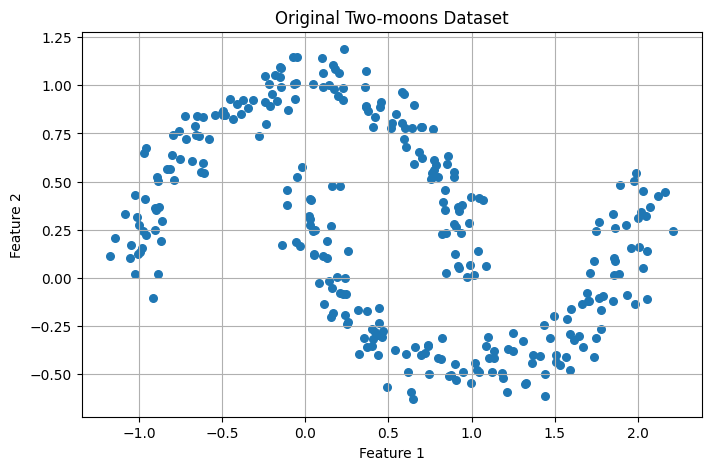

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], X[:, 1], s= 30)

plt.title("Original Two-moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.grid(True)
plt.show()

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original shape: ",X.shape)
print("Scaled shape: ",X_scaled.shape)

print("\nScaled data first 5 rows: ",np.round(X_scaled[:5],2))

Original shape:  (300, 2)
Scaled shape:  (300, 2)

Scaled data first 5 rows:  [[ 0.18 -1.22]
 [ 1.7  -0.78]
 [-0.7   0.4 ]
 [ 0.46  0.02]
 [ 0.78 -1.5 ]]


In [15]:
dbscan = DBSCAN(eps=0.3, min_samples=5)

labels = dbscan.fit_predict(X_scaled)

print("Cluster lables: ",np.unique(labels))

print("\nNumber of clusters (excluding noise): ",len(set(labels)) - (1 if -1 in labels else 0))

print("Number of noise points: ",np.sum(labels == -1))

Cluster lables:  [0 1]

Number of clusters (excluding noise):  2
Number of noise points:  0


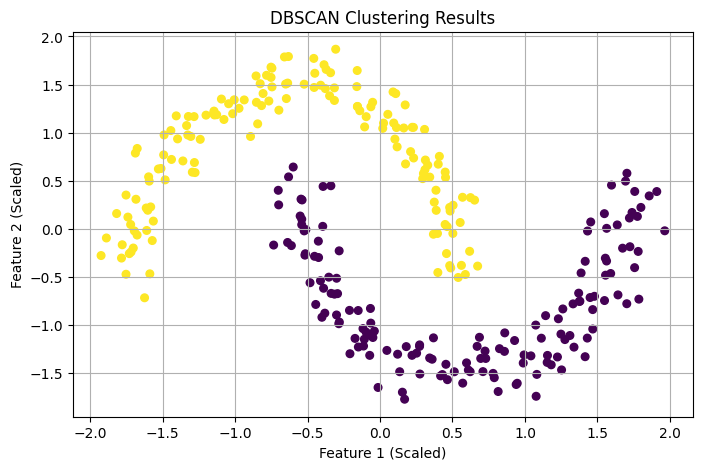

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap='viridis',
    s=30
)

plt.title("DBSCAN Clustering Results")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")

plt.grid(True)
plt.show()

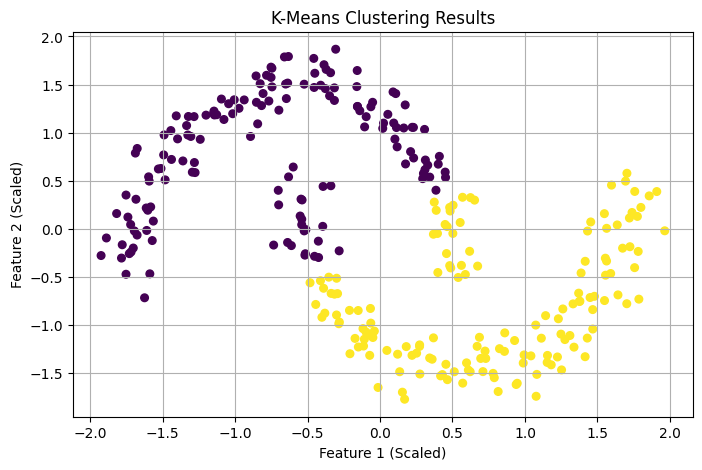

In [22]:
from sklearn.cluster import KMeans

#Apply KMeans with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

kmeans_label = kmeans.fit_predict(X_scaled)

#Visualize KMeans clustering
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_label,
    cmap='viridis',
    s=30
)

plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")

plt.grid(True)
plt.show()

In [24]:
print("DBSCAN Cluster counts: ")
for cluster in np.unique(labels):
  print(f"cluster {cluster}: {np.sum(labels == cluster)} points")

print("\nK-Means Cluster counts: ")
for cluster in np.unique(kmeans_label):
  print(f"cluster {cluster}: {np.sum(kmeans_label == cluster)} points")


DBSCAN Cluster counts: 
cluster 0: 150 points
cluster 1: 150 points

K-Means Cluster counts: 
cluster 0: 150 points
cluster 1: 150 points


In [26]:
from sklearn.metrics import silhouette_score

dbscan_score = silhouette_score(X_scaled, labels)
kmeans_score = silhouette_score(X_scaled, kmeans_label)

print("DBSCAN Silhouette Score: ",round(dbscan_score, 4))
print("K-Means Silhouette Score: ",round(kmeans_score, 4))

DBSCAN Silhouette Score:  0.3803
K-Means Silhouette Score:  0.4936


In [27]:
eps_values = [0.15, 0.2, 0.3, 0.4, 0.5]

for eps_value in eps_values:
  model = DBSCAN(eps=eps_value, min_samples=5)
  test_labels = model.fit_predict(X_scaled)

  n_clusters = len(set(test_labels) - {-1})
  n_noise = np.sum(test_labels == -1)

  print(
      f"eps={eps_value}: "
      f"clusters={n_clusters}: "
      f"noise={n_noise}: "
  )

eps=0.15: clusters=18: noise=53: 
eps=0.2: clusters=7: noise=10: 
eps=0.3: clusters=2: noise=0: 
eps=0.4: clusters=2: noise=0: 
eps=0.5: clusters=1: noise=0: 
